# Assignment 11: Part-of-Speech Tagging with Hidden Markov Models

A first-order hidden Markov model (HMM) POS tagger is implemented here from scratch with plain Python and NumPy. The transition table, the emission table, the joint sequence probability, and Viterbi decoding are all written explicitly; no POS tagger or HMM library supplies a result.

The target sentence is

$$\text{सीता बगीचे से सुंदर लाल फूल तोड़ती है ।}$$

with the tagset $\{\text{NNP},\text{NN},\text{PSP},\text{JJ},\text{VM},\text{VAUX}\}$. The final danda `।` is punctuation, not a word in the tagset, so it is excluded from the observation sequence.

The notebook follows the five questions: Q1 builds the tables, Q2 scores one candidate path, Q3 runs Viterbi, Q4 introduces lexical ambiguity in सुंदर, and Q5 tags four additional sentences. A brute-force enumeration of every tag sequence checks the Viterbi result at the end.

In [1]:
import itertools
import math
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = ["Noto Sans Devanagari", "DejaVu Sans"]

START, END = "<s>", "</s>"
TAGS = ["NNP", "NN", "PSP", "JJ", "VM", "VAUX"]
NEXT_STATES = TAGS + [END]

TAG_NAMES = {
    "NNP": "proper noun",
    "NN": "common noun",
    "PSP": "postposition",
    "JJ": "adjective",
    "VM": "main verb",
    "VAUX": "auxiliary verb",
}

WORDS = ["सीता", "बगीचे", "से", "सुंदर", "लाल", "फूल", "तोड़ती", "है"]
TARGET = ["सीता", "बगीचे", "से", "सुंदर", "लाल", "फूल", "तोड़ती", "है"]
TARGET_TAGS = ["NNP", "NN", "PSP", "JJ", "JJ", "NN", "VM", "VAUX"]

print("Target sentence :", " ".join(TARGET))
print("Candidate tags  :", " → ".join(TARGET_TAGS))
print("Tag inventory   :", ", ".join(f"{t} ({TAG_NAMES[t]})" for t in TAGS))

Target sentence : सीता बगीचे से सुंदर लाल फूल तोड़ती है
Candidate tags  : NNP → NN → PSP → JJ → JJ → NN → VM → VAUX
Tag inventory   : NNP (proper noun), NN (common noun), PSP (postposition), JJ (adjective), VM (main verb), VAUX (auxiliary verb)


## A small annotated corpus

The parameters are estimated from the nine short sentences below. Every word of the target sentence occurs in this training set, but **the target sentence itself is not in the training set**: it is decoded as unseen data. The sentences are deliberately short so the count tables fit on one screen and every probability can be checked by hand.

The annotation follows ordinary Hindi syntax:

| Word | Tag | Gloss | Why this tag |
| --- | --- | --- | --- |
| सीता | NNP | Sita | personal name, proper noun |
| बगीचे | NN | garden (oblique) | common noun; oblique form before a postposition |
| से | PSP | from | postposition |
| सुंदर | JJ | beautiful | adjective modifying फूल |
| लाल | JJ | red | adjective modifying फूल |
| फूल | NN | flower(s) | common noun |
| तोड़ती | VM | plucks | main verb, feminine singular agreeing with सीता |
| है | VAUX | is | auxiliary verb |

Hindi is verb-final: the main verb precedes the auxiliary, adjectives precede the noun they modify, and a postposition follows its noun phrase. Those regularities are exactly what the transition table captures.

In [2]:
# Each entry is (word list, tag list).  The target sentence is deliberately absent.
TAGGED_CORPUS = [
    (["सीता", "फूल", "तोड़ती", "है"], ["NNP", "NN", "VM", "VAUX"]),
    (["सुंदर", "लाल", "फूल", "है"], ["JJ", "JJ", "NN", "VAUX"]),
    (["लाल", "फूल", "सुंदर", "है"], ["JJ", "NN", "JJ", "VAUX"]),
    (["सीता", "बगीचे", "से", "फूल", "तोड़ती", "है"], ["NNP", "NN", "PSP", "NN", "VM", "VAUX"]),
    (["बगीचे", "से", "सुंदर", "फूल", "है"], ["NN", "PSP", "JJ", "NN", "VAUX"]),
    (["सीता", "सुंदर", "है"], ["NNP", "JJ", "VAUX"]),
    (["फूल", "लाल", "है"], ["NN", "JJ", "VAUX"]),
    (["सीता", "तोड़ती", "है"], ["NNP", "VM", "VAUX"]),
    (["सुंदर", "फूल", "तोड़ती", "है"], ["JJ", "NN", "VM", "VAUX"]),
]

for words, tags in TAGGED_CORPUS:
    assert len(words) == len(tags)
    assert all(w in WORDS for w in words)
    assert all(t in TAGS for t in tags)
assert TARGET not in [words for words, _ in TAGGED_CORPUS]
assert len(TAGGED_CORPUS) == 9

for i, (words, tags) in enumerate(TAGGED_CORPUS, 1):
    print(f"{i:2d}. " + " ".join(f"{w}/{t}" for w, t in zip(words, tags)))

 1. सीता/NNP फूल/NN तोड़ती/VM है/VAUX
 2. सुंदर/JJ लाल/JJ फूल/NN है/VAUX
 3. लाल/JJ फूल/NN सुंदर/JJ है/VAUX
 4. सीता/NNP बगीचे/NN से/PSP फूल/NN तोड़ती/VM है/VAUX
 5. बगीचे/NN से/PSP सुंदर/JJ फूल/NN है/VAUX
 6. सीता/NNP सुंदर/JJ है/VAUX
 7. फूल/NN लाल/JJ है/VAUX
 8. सीता/NNP तोड़ती/VM है/VAUX
 9. सुंदर/JJ फूल/NN तोड़ती/VM है/VAUX


## Q1. HMM representation

The HMM has two layers:

- **Hidden states** $t_i \in \{\text{NNP},\text{NN},\text{PSP},\text{JJ},\text{VM},\text{VAUX}\}$ are the POS tags.
- **Observations** $w_i$ are the words. The observed sentence is $W=(w_1,\dots,w_n)$; the hidden tag sequence is $T=(t_1,\dots,t_n)$.

A first-order HMM makes two assumptions:

$$
P(t_i \mid t_1,\dots,t_{i-1}) = P(t_i \mid t_{i-1}),
\qquad
P(w_i \mid T, w_1,\dots,w_{i-1}) = P(w_i \mid t_i).
$$

The joint probability of a sentence and a tag sequence therefore factorizes as

$$
P(W,T)=P(t_1\mid \text{START})\prod_{i=2}^{n}P(t_i\mid t_{i-1})
\prod_{i=1}^{n}P(w_i\mid t_i)\;P(\text{END}\mid t_n).
$$

The transition probabilities are estimated from counts by maximum likelihood with add-$\alpha$ smoothing:

$$
P(t_i=j\mid t_{i-1}=i)=\frac{C(i,j)+\alpha}{C(i)+\alpha|S|},
\qquad |S|=|\text{TAGS}|+1=7,
$$

where the extra state is `END`. The emission probabilities are estimated by maximum likelihood:

$$
P(w\mid t)=\frac{C(w,t)}{C(t)}.
$$

The tables are stored as dictionaries of dictionaries (`dict[str, dict[str, float]]`), which keeps the zeros implicit and makes lookup by tag or by word direct. A dense NumPy matrix is used only for display and plotting.

In [3]:
def print_table(headers, rows, aligns=None):
    '''Print a small fixed-width table; aligns are '<' or '>' per column.'''
    rows = [[str(c) for c in r] for r in rows]
    headers = [str(h) for h in headers]
    widths = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    aligns = aligns or ["<"] * len(headers)
    line = "  ".join(f"{h:{aligns[i]}{widths[i]}}" for i, h in enumerate(headers))
    print(line)
    print("-" * len(line))
    for r in rows:
        print("  ".join(f"{c:{aligns[i]}{widths[i]}}" for i, c in enumerate(r)))


def show_state(state):
    return "START" if state == START else "END" if state == END else state


transition_counts = {p: Counter() for p in [START] + TAGS}
emission_counts = {t: Counter() for t in TAGS}
tag_counts = Counter()

for words, tags in TAGGED_CORPUS:
    prev = START
    for word, tag in zip(words, tags):
        transition_counts[prev][tag] += 1
        emission_counts[tag][word] += 1
        tag_counts[tag] += 1
        prev = tag
    transition_counts[prev][END] += 1

ALPHA = 0.1
transition = {}
for prev in [START] + TAGS:
    total = sum(transition_counts[prev].values())
    transition[prev] = {
        nxt: (transition_counts[prev][nxt] + ALPHA) / (total + ALPHA * len(NEXT_STATES))
        for nxt in NEXT_STATES
    }

emission = {
    tag: {word: emission_counts[tag][word] / tag_counts[tag]
          for word in WORDS if emission_counts[tag][word] > 0}
    for tag in TAGS
}

print("Transition counts C(i, j)")
rows = [[show_state(prev)] + [transition_counts[prev][nxt] for nxt in NEXT_STATES]
        + [sum(transition_counts[prev].values())]
        for prev in [START] + TAGS]
print_table(["from \\ to"] + [show_state(nxt) for nxt in NEXT_STATES] + ["total"], rows,
            aligns=["<"] + [">"] * (len(NEXT_STATES) + 1))

print("\nTransition probabilities P(j | i)")
rows = [[show_state(prev)] + [f"{transition[prev][nxt]:.4f}" for nxt in NEXT_STATES]
        for prev in [START] + TAGS]
print_table(["from \\ to"] + [show_state(nxt) for nxt in NEXT_STATES], rows,
            aligns=["<"] + [">"] * len(NEXT_STATES))

print("\nEmission counts C(w, t)")
rows = [[tag] + [emission_counts[tag][word] for word in WORDS] + [tag_counts[tag]]
        for tag in TAGS]
print_table(["tag"] + WORDS + ["total"], rows,
            aligns=["<"] + [">"] * (len(WORDS) + 1))

print("\nEmission probabilities P(w | t)")
rows = [[word] + [f"{emission[tag].get(word, 0.0):.4f}" for tag in TAGS]
        for word in WORDS]
print_table(["word"] + TAGS, rows, aligns=["<"] + [">"] * len(TAGS))

# Every transition row is a distribution over the six tags plus END.
for prev in [START] + TAGS:
    assert abs(sum(transition[prev].values()) - 1.0) < 1e-12
# Every emission column is a distribution over the eight-word vocabulary.
for tag in TAGS:
    assert abs(sum(emission[tag].get(word, 0.0) for word in WORDS) - 1.0) < 1e-12
print("\nRow and column normalisation checks passed.")

Transition counts C(i, j)
from \ to  NNP  NN  PSP  JJ  VM  VAUX  END  total
-------------------------------------------------
START        4   2    0   3   0     0    0      9
NNP          0   2    0   1   1     0    0      4
NN           0   0    2   2   3     2    0      9
PSP          0   1    0   1   0     0    0      2
JJ           0   4    0   1   0     3    0      8
VM           0   0    0   0   0     4    0      4
VAUX         0   0    0   0   0     0    9      9

Transition probabilities P(j | i)
from \ to     NNP      NN     PSP      JJ      VM    VAUX     END
-----------------------------------------------------------------
START      0.4227  0.2165  0.0103  0.3196  0.0103  0.0103  0.0103
NNP        0.0213  0.4468  0.0213  0.2340  0.2340  0.0213  0.0213
NN         0.0103  0.0103  0.2165  0.2165  0.3196  0.2165  0.0103
PSP        0.0370  0.4074  0.0370  0.4074  0.0370  0.0370  0.0370
JJ         0.0115  0.4713  0.0115  0.1264  0.0115  0.3563  0.0115
VM         0.0213  0.0213  

The transition table is sparse and linguistically sensible. `START` goes to `NNP` (0.4227), `NN` (0.2165), or `JJ` (0.3196), the three ways a Hindi noun phrase can begin in this vocabulary. `NNP` goes to `NN` with 0.4468, `NN` goes to `VM` with 0.3196, `VM` goes to `VAUX` with 0.8723, and `VAUX` goes to `END` with 0.9381. The add-$\alpha$ floor is visible as the small 0.0103–0.0370 entries; it keeps every transition finite without changing the ranking of the observed transitions.

The emission table is even sparser because the training vocabulary is closed and each word has one lexical tag. `सीता` is emitted only by `NNP`, `से` only by `PSP`, `तोड़ती` only by `VM`, and `है` only by `VAUX`. Within `NN`, the two words split by frequency: `फूल` gets 7/9 = 0.7778 and `बगीचे` gets 2/9 = 0.2222. Within `JJ`, `सुंदर` gets 5/8 = 0.6250 and `लाल` gets 3/8 = 0.3750. Those four numbers drive most of Q2.

## Q2. Probability of the candidate sequence

The candidate sequence is

$$
\text{NNP}\to\text{NN}\to\text{PSP}\to\text{JJ}\to\text{JJ}\to\text{NN}\to\text{VM}\to\text{VAUX}.
$$

Its joint probability with the words is the product of nine transition factors (including `START` and `END`) and eight emission factors:

$$
P(W,T)=
P(\text{NNP}\mid\text{START})P(\text{सीता}\mid\text{NNP})
P(\text{NN}\mid\text{NNP})P(\text{बगीचे}\mid\text{NN})
\cdots
P(\text{VAUX}\mid\text{VM})P(\text{है}\mid\text{VAUX})
P(\text{END}\mid\text{VAUX}).
$$

The notebook prints each factor and the running product, then repeats the calculation in log space. A product of seventeen factors, most below 1, can underflow quickly; the log sum is the numerically stable equivalent.

In [4]:
def logp(p):
    return math.log(p) if p > 0 else -math.inf


def sequence_log_probability(words, tags, trans=None, emis=None):
    '''Log P(W, T) for one word/tag sequence, including START and END.'''
    trans = trans or transition
    emis = emis or emission
    if len(words) != len(tags):
        raise ValueError("words and tags must have equal length")
    total = logp(trans[START][tags[0]]) + logp(emis[tags[0]].get(words[0], 0.0))
    for i in range(1, len(words)):
        total += logp(trans[tags[i - 1]][tags[i]])
        total += logp(emis[tags[i]].get(words[i], 0.0))
    total += logp(trans[tags[-1]][END])
    return total


terms = [("START→" + TARGET_TAGS[0], transition[START][TARGET_TAGS[0]]),
         (TARGET[0] + "|" + TARGET_TAGS[0], emission[TARGET_TAGS[0]][TARGET[0]])]
for i in range(1, len(TARGET)):
    terms.append((TARGET_TAGS[i - 1] + "→" + TARGET_TAGS[i],
                  transition[TARGET_TAGS[i - 1]][TARGET_TAGS[i]]))
    terms.append((TARGET[i] + "|" + TARGET_TAGS[i],
                  emission[TARGET_TAGS[i]][TARGET[i]]))
terms.append((TARGET_TAGS[-1] + "→END", transition[TARGET_TAGS[-1]][END]))

cumulative = 1.0
rows = []
for step, (name, p) in enumerate(terms, 1):
    cumulative *= p
    rows.append([step, name, f"{p:.6f}", f"{math.log(p):.4f}", f"{cumulative:.6e}"])
print_table(["step", "term", "probability", "log", "cumulative"], rows,
            aligns=[">", "<", ">", ">", ">"])

sequence_log = sequence_log_probability(TARGET, TARGET_TAGS)
transition_log = sum(math.log(p) for name, p in terms if "→" in name)
emission_log = sum(math.log(p) for name, p in terms if "|" in name)
print(f"\ntransition product = {math.exp(transition_log):.6e}   (log {transition_log:.6f})")
print(f"emission product   = {math.exp(emission_log):.6e}   (log {emission_log:.6f})")
print(f"joint P(W,T)       = {math.exp(sequence_log):.6e}   (log {sequence_log:.6f})")

step  term       probability      log    cumulative
---------------------------------------------------
   1  START→NNP     0.422680  -0.8611  4.226804e-01
   2  सीता|NNP      1.000000   0.0000  4.226804e-01
   3  NNP→NN        0.446809  -0.8056  1.888572e-01
   4  बगीचे|NN      0.222222  -1.5041  4.196827e-02
   5  NN→PSP        0.216495  -1.5302  9.085914e-03
   6  से|PSP        1.000000   0.0000  9.085914e-03
   7  PSP→JJ        0.407407  -0.8979  3.701669e-03
   8  सुंदर|JJ      0.625000  -0.4700  2.313543e-03
   9  JJ→JJ         0.126437  -2.0680  2.925169e-04
  10  लाल|JJ        0.375000  -0.9808  1.096938e-04
  11  JJ→NN         0.471264  -0.7523  5.169480e-05
  12  फूल|NN        0.777778  -0.2513  4.020707e-05
  13  NN→VM         0.319588  -1.1407  1.284968e-05
  14  तोड़ती|VM     1.000000   0.0000  1.284968e-05
  15  VM→VAUX       0.872340  -0.1366  1.120930e-05
  16  है|VAUX       1.000000   0.0000  1.120930e-05
  17  VAUX→END      0.938144  -0.0639  1.051594e-05

transition 

The joint probability is

$$
P(W,T)=1.051594\times10^{-5},\qquad \log P(W,T)=-11.462619.
$$

The transition part contributes $2.5959\times10^{-4}$ and the emission part contributes $4.0509\times10^{-2}$. The smallest transition factor is `JJ→JJ` at 0.1264, not because repeated adjectives are impossible but because the training corpus contains only one such transition. The smallest emission factor is `बगीचे|NN` at 0.2222, simply because `फूल` is much more frequent in the corpus. Q3 shows that this candidate is in fact the Viterbi optimum, so its probability is also the best-path probability.

This is a **joint** probability $P(W,T)$, not the marginal $P(W)$. The marginal likelihood of the sentence would sum this quantity over all $6^8$ tag sequences, which is exactly what the brute-force check in the last section does implicitly.

## Q3. Viterbi decoding from scratch

Define the Viterbi variable

$$
\delta_i(j)=\max_{t_1,\dots,t_{i-1}}P(t_1,\dots,t_{i-1},t_i=j,w_1,\dots,w_i).
$$

It is the best joint probability of any tag prefix ending in tag $j$ at position $i$. The first-order Markov assumption gives the recursion

$$
\delta_i(j)=\max_{k\in S}\left[\delta_{i-1}(k)\,P(j\mid k)\right]P(w_i\mid j),
$$

and the backpointer stores the maximizing predecessor:

$$
\psi_i(j)=\arg\max_{k\in S}\left[\delta_{i-1}(k)\,P(j\mid k)\right].
$$

Initialization is $\delta_1(j)=P(j\mid\text{START})P(w_1\mid j)$. Termination adds the end transition, $P^*=\max_j \delta_n(j)P(\text{END}\mid j)$, and backtracking follows $t_i^*=\psi_{i+1}(t_{i+1}^*)$ from the best final tag.

The implementation stores $\log\delta$ rather than $\delta$. The recursion becomes a sum, zero probabilities become $-\infty$, and no product underflows. The `back` table stores `None` for an impossible state so the printed backpointer table does not pretend that a predecessor exists.

In [5]:
LOG_TRANSITION = {p: {q: logp(v) for q, v in row.items()}
                  for p, row in transition.items()}
LOG_EMISSION = {t: {w: logp(v) for w, v in row.items()}
                for t, row in emission.items()}


def viterbi(words, trans=None, emis=None):
    '''Return (best tag path, log-delta table, backpointer table, best log score).'''
    trans = trans or transition
    emis = emis or emission
    n = len(words)
    delta = [dict() for _ in range(n)]
    back = [dict() for _ in range(n)]

    for tag in TAGS:
        delta[0][tag] = logp(trans[START][tag]) + logp(emis[tag].get(words[0], 0.0))
        back[0][tag] = START if math.isfinite(delta[0][tag]) else None

    for i in range(1, n):
        for tag in TAGS:
            candidates = {prev: delta[i - 1][prev] + logp(trans[prev][tag])
                          for prev in TAGS}
            best_prev = max(candidates, key=candidates.get)
            delta[i][tag] = candidates[best_prev] + logp(emis[tag].get(words[i], 0.0))
            back[i][tag] = best_prev if math.isfinite(delta[i][tag]) else None

    final = {tag: delta[-1][tag] + logp(trans[tag][END]) for tag in TAGS}
    best_last = max(final, key=final.get)
    path = [best_last]
    for i in range(n - 1, 0, -1):
        path.append(back[i][path[-1]])
    path.reverse()
    return path, delta, back, final[best_last]


def fmt_log(value):
    return "−∞" if not math.isfinite(value) else f"{value:.3f}"


def fmt_back(value):
    return "—" if value is None else ("START" if value == START else value)


def print_viterbi(words, delta, back):
    rows = [[word] + [fmt_log(delta[i][tag]) for tag in TAGS]
            for i, word in enumerate(words)]
    print_table(["word"] + TAGS, rows, aligns=["<"] + [">"] * len(TAGS))
    print("\nBackpointers ψ_i(t) = argmax predecessor")
    rows = [[word] + [fmt_back(back[i][tag]) for tag in TAGS]
            for i, word in enumerate(words)]
    print_table(["word"] + TAGS, rows, aligns=["<"] + [">"] * len(TAGS))


path, delta, back, best_log = viterbi(TARGET)
print("Viterbi log-probability table δ")
print_viterbi(TARGET, delta, back)
print("\nBest path :", " → ".join(path))
print(f"log P*     = {best_log:.6f}")
print(f"P*         = {math.exp(best_log):.6e}")
print("Path score =", f"{sequence_log_probability(TARGET, path):.6f}")

Viterbi log-probability table δ
word       NNP       NN     PSP      JJ       VM     VAUX
---------------------------------------------------------
सीता    -0.861       −∞      −∞      −∞       −∞       −∞
बगीचे       −∞   -3.171      −∞      −∞       −∞       −∞
से          −∞       −∞  -4.701      −∞       −∞       −∞
सुंदर       −∞       −∞      −∞  -6.069       −∞       −∞
लाल         −∞       −∞      −∞  -9.118       −∞       −∞
फूल         −∞  -10.121      −∞      −∞       −∞       −∞
तोड़ती      −∞       −∞      −∞      −∞  -11.262       −∞
है          −∞       −∞      −∞      −∞       −∞  -11.399

Backpointers ψ_i(t) = argmax predecessor
word      NNP   NN  PSP   JJ  VM  VAUX
--------------------------------------
सीता    START    —    —    —   —     —
बगीचे       —  NNP    —    —   —     —
से          —    —   NN    —   —     —
सुंदर       —    —    —  PSP   —     —
लाल         —    —    —   JJ   —     —
फूल         —   JJ    —    —   —     —
तोड़ती      —    —    —    —  NN  

The Viterbi table has only one finite entry per column because the base emission table is deterministic: each word can be emitted by exactly one tag. The finite entries are the running best scores

$$
-0.861,\;-3.171,\;-4.701,\;-6.069,\;-9.118,\;-10.121,\;-11.262,\;-11.399,
$$

and the final score after the `VAUX→END` factor 0.9381 is $-11.462619$. Backtracking from `VAUX` gives `VM ← NN ← JJ ← JJ ← PSP ← NN ← NNP`, i.e.

$$
\text{NNP}\to\text{NN}\to\text{PSP}\to\text{JJ}\to\text{JJ}\to\text{NN}\to\text{VM}\to\text{VAUX}.
$$

This is the same path that Q2 scored, which is a useful consistency check: Q2 evaluated one candidate, and Q3 found that no other candidate beats it. The base table is a special case; Q4 makes the table genuinely ambiguous and the trellis denser.

The Viterbi recursion does $|S|$ comparisons for each of $|S|$ states at each of $n$ positions, so the time complexity is $O(n|S|^2)$ and the memory is $O(n|S|)$ because the backpointer table must be retained for backtracking.

## Q4. Ambiguous POS tagging

The base emission table treats सुंदर as an adjective only. To model lexical ambiguity, give it a second reading as a common noun and renormalise the `NN` column so it still sums to 1. If the new `NN` mass for सुंदर is $m$, the other `NN` words keep their relative proportions:

$$
P(\text{बगीचे}\mid\text{NN})=(1-m)\frac{0.2222}{0.2222+0.7778},
\qquad
P(\text{फूल}\mid\text{NN})=(1-m)\frac{0.7778}{0.2222+0.7778}.
$$

The `JJ` column is left unchanged: $P(\text{सुंदर}\mid\text{JJ})=0.6250$ and $P(\text{लाल}\mid\text{JJ})=0.3750$. Two values of $m$ are tested, 0.25 and 0.40. Then one transition is changed: $P(\text{PSP}\to\text{JJ})$ is lowered from 0.4074 to 0.10 and the released mass is distributed over the other successors of `PSP` in proportion to their old values.

In [6]:
def ambiguous_emission(nn_mass):
    '''Copy the base emission table and give सुंदर an NN reading of mass nn_mass.'''
    emis = {tag: dict(emission[tag]) for tag in TAGS}
    others = [word for word in emission["NN"] if word != "सुंदर"]
    base_mass = sum(emission["NN"][word] for word in others)
    emis["NN"]["सुंदर"] = nn_mass
    for word in others:
        emis["NN"][word] = emission["NN"][word] / base_mass * (1.0 - nn_mass)
    return emis


for mass in (0.25, 0.40):
    emis = ambiguous_emission(mass)
    print(f"\nEmission table with P(सुंदर|NN) = {mass:.2f}")
    rows = [[word] + [f"{emis[tag].get(word, 0.0):.4f}" for tag in TAGS]
            for word in WORDS]
    print_table(["word"] + TAGS, rows, aligns=["<"] + [">"] * len(TAGS))
    for tag in TAGS:
        assert abs(sum(emis[tag].get(word, 0.0) for word in WORDS) - 1.0) < 1e-12


Emission table with P(सुंदर|NN) = 0.25
word       NNP      NN     PSP      JJ      VM    VAUX
------------------------------------------------------
सीता    1.0000  0.0000  0.0000  0.0000  0.0000  0.0000
बगीचे   0.0000  0.1667  0.0000  0.0000  0.0000  0.0000
से      0.0000  0.0000  1.0000  0.0000  0.0000  0.0000
सुंदर   0.0000  0.2500  0.0000  0.6250  0.0000  0.0000
लाल     0.0000  0.0000  0.0000  0.3750  0.0000  0.0000
फूल     0.0000  0.5833  0.0000  0.0000  0.0000  0.0000
तोड़ती  0.0000  0.0000  0.0000  0.0000  1.0000  0.0000
है      0.0000  0.0000  0.0000  0.0000  0.0000  1.0000

Emission table with P(सुंदर|NN) = 0.40
word       NNP      NN     PSP      JJ      VM    VAUX
------------------------------------------------------
सीता    1.0000  0.0000  0.0000  0.0000  0.0000  0.0000
बगीचे   0.0000  0.1333  0.0000  0.0000  0.0000  0.0000
से      0.0000  0.0000  1.0000  0.0000  0.0000  0.0000
सुंदर   0.0000  0.4000  0.0000  0.6250  0.0000  0.0000
लाल     0.0000  0.0000  0.0000  0.3750  

In [7]:
q4_results = []
for mass in (0.25, 0.40):
    emis = ambiguous_emission(mass)
    path, delta, back, best_log = viterbi(TARGET, emis=emis)
    q4_results.append((f"P(सुंदर|NN)={mass:.2f}", path, best_log, delta[3]["JJ"], delta[3]["NN"]))
    print(f"mass = {mass:.2f}: {' → '.join(path)}")
    print(f"  सुंदर is tagged {path[3]};  log P* = {best_log:.6f};  P* = {math.exp(best_log):.6e}")
    print(f"  log δ at सुंदर:  JJ = {fmt_log(delta[3]['JJ'])},  NN = {fmt_log(delta[3]['NN'])}")

# One transition change: PSP -> JJ is made much less likely.
trans_context = {prev: dict(row) for prev, row in transition.items()}
old_psp = trans_context["PSP"]
rest = {nxt: value for nxt, value in old_psp.items() if nxt != "JJ"}
rest_total = sum(rest.values())
trans_context["PSP"] = {
    nxt: (0.10 if nxt == "JJ" else value / rest_total * 0.90)
    for nxt, value in old_psp.items()
}
print("\nPSP row before:", {show_state(nxt): round(value, 4) for nxt, value in transition["PSP"].items()})
print("PSP row after :", {show_state(nxt): round(value, 4) for nxt, value in trans_context["PSP"].items()})

path, delta, back, best_log = viterbi(TARGET, trans=trans_context, emis=ambiguous_emission(0.25))
q4_results.append(("PSP→JJ=0.10", path, best_log, delta[3]["JJ"], delta[3]["NN"]))
print(f"transition change: {' → '.join(path)}")
print(f"  सुंदर is tagged {path[3]};  log P* = {best_log:.6f};  P* = {math.exp(best_log):.6e}")

print("\nQ4 summary")
print_table(["configuration", "सुंदर", "log P*", "P*", "log δ JJ", "log δ NN"],
            [[name, path[3], f"{score:.4f}", f"{math.exp(score):.3e}",
              fmt_log(dj), fmt_log(dn)]
             for name, path, score, dj, dn in q4_results],
            aligns=["<", "^", ">", ">", ">", ">"])

mass = 0.25: NNP → NN → PSP → JJ → JJ → NN → VM → VAUX
  सुंदर is tagged JJ;  log P* = -12.037983;  P* = 5.915215e-06
  log δ at सुंदर:  JJ = -6.357,  NN = -7.273
mass = 0.40: NNP → NN → PSP → NN → JJ → NN → VM → VAUX
  सुंदर is tagged NN;  log P* = -12.392733;  P* = 4.148629e-06
  log δ at सुंदर:  JJ = -6.580,  NN = -7.026

PSP row before: {'NNP': 0.037, 'NN': 0.4074, 'PSP': 0.037, 'JJ': 0.4074, 'VM': 0.037, 'VAUX': 0.037, 'END': 0.037}
PSP row after : {'NNP': 0.0563, 'NN': 0.6188, 'PSP': 0.0563, 'JJ': 0.1, 'VM': 0.0563, 'VAUX': 0.0563, 'END': 0.0563}
transition change: NNP → NN → PSP → NN → JJ → NN → VM → VAUX
  सुंदर is tagged NN;  log P* = -11.998562;  P* = 6.153057e-06

Q4 summary
configuration     सुंदर    log P*         P*  log δ JJ  log δ NN
----------------------------------------------------------------
P(सुंदर|NN)=0.25   JJ    -12.0380  5.915e-06    -6.357    -7.273
P(सुंदर|NN)=0.40   NN    -12.3927  4.149e-06    -6.580    -7.026
PSP→JJ=0.10        NN    -11.9986  6.153e-06 

At $m=0.25$ the added noun reading is not enough: सुंदर is still tagged `JJ`. At $m=0.40$ the same word is tagged `NN` and the path becomes `NNP NN PSP NN JJ NN VM VAUX`. The local comparison explains both outcomes. Ignoring the common prefix and suffix, the two competing two-position products are

$$
\text{JJ path}: P(\text{PSP}\to\text{JJ})P(\text{JJ}\to\text{JJ})P(\text{सुंदर}\mid\text{JJ})P(\text{लाल}\mid\text{JJ})
=0.4074\times0.1264\times0.6250\times0.3750=0.01207,
$$

$$
\text{NN path}: P(\text{PSP}\to\text{NN})P(\text{NN}\to\text{JJ})P(\text{सुंदर}\mid\text{NN})P(\text{लाल}\mid\text{JJ})
=0.4074\times0.2165\times m\times0.3750.
$$

At $m=0.25$ the NN path is $0.00827<0.01207$, so `JJ` wins. At $m=0.40$ it is $0.01323>0.01207$, so `NN` wins even though $P(\text{सुंदर}\mid\text{JJ})=0.6250$ is still larger than $P(\text{सुंदर}\mid\text{NN})=0.40$. The transition `NN→JJ` (0.2165) is almost twice `JJ→JJ` (0.1264), and that context effect tips the product.

Lowering $P(\text{PSP}\to\text{JJ})$ to 0.10 has the same qualitative effect more strongly. The released mass makes $P(\text{PSP}\to\text{NN})=0.6188$, so the NN reading is now supported by both the preceding postposition and the following adjective transition. The selected tag flips to `NN` even at $m=0.25$.

The lesson is that Viterbi maximises a **product**, not a single emission. A tag with a lower word likelihood can win if it enables a much better transition into the next tag. Conversely, a strong emission can override a weak transition. Context and word likelihood are not alternatives; they are multiplied, and the backpointer table records which predecessor won at each cell.

## Q5. Tagging additional sentences

Four short sentences are decoded with the ambiguous emission table from Q4 ($m=0.25$). All four are **unseen** word sequences: none is identical to a training sentence. They reuse only the eight-word vocabulary.

| # | Sentence | Expected shape |
| --- | --- | --- |
| 1 | सीता लाल फूल तोड़ती है | NNP JJ NN VM VAUX |
| 2 | बगीचे से सुंदर फूल तोड़ती है | NN PSP JJ NN VM VAUX |
| 3 | सुंदर फूल लाल है | JJ NN JJ VAUX |
| 4 | सीता बगीचे से लाल फूल तोड़ती है | NNP NN PSP JJ NN VM VAUX |

For each sentence the notebook prints the Viterbi table, the backpointer table, and the recovered path.

In [8]:
Q5_SENTENCES = [
    ["सीता", "लाल", "फूल", "तोड़ती", "है"],
    ["बगीचे", "से", "सुंदर", "फूल", "तोड़ती", "है"],
    ["सुंदर", "फूल", "लाल", "है"],
    ["सीता", "बगीचे", "से", "लाल", "फूल", "तोड़ती", "है"],
]
q5_emission = ambiguous_emission(0.25)
q5_rows = []

for index, words in enumerate(Q5_SENTENCES, 1):
    assert all(word in WORDS for word in words)
    assert words not in [train_words for train_words, _ in TAGGED_CORPUS]
    path, delta, back, best_log = viterbi(words, emis=q5_emission)
    print(f"\nQ5.{index}: {' '.join(words)}")
    print_viterbi(words, delta, back)
    print("Prediction :", " → ".join(path))
    print(f"log P*     = {best_log:.6f}")
    print(f"P*         = {math.exp(best_log):.6e}")
    print(f"P*^(1/n)   = {math.exp(best_log / len(words)):.6f}")
    q5_rows.append([index, " ".join(words), " ".join(path),
                    f"{best_log:.4f}", f"{math.exp(best_log):.4e}",
                    f"{math.exp(best_log / len(words)):.4f}"])

print("\nQ5 summary")
print_table(["#", "sentence", "predicted tags", "log P*", "P*", "P*^(1/n)"],
            q5_rows, aligns=[">", "<", "<", ">", ">", ">"])


Q5.1: सीता लाल फूल तोड़ती है
word       NNP      NN  PSP      JJ      VM    VAUX
---------------------------------------------------
सीता    -0.861      −∞   −∞      −∞      −∞      −∞
लाल         −∞      −∞   −∞  -3.294      −∞      −∞
फूल         −∞  -4.586   −∞      −∞      −∞      −∞
तोड़ती      −∞      −∞   −∞      −∞  -5.726      −∞
है          −∞      −∞   −∞      −∞      −∞  -5.863

Backpointers ψ_i(t) = argmax predecessor
word      NNP  NN  PSP   JJ  VM  VAUX
-------------------------------------
सीता    START   —    —    —   —     —
लाल         —   —    —  NNP   —     —
फूल         —  JJ    —    —   —     —
तोड़ती      —   —    —    —  NN     —
है          —   —    —    —   —    VM
Prediction : NNP → JJ → NN → VM → VAUX
log P*     = -5.926704
P*         = 2.667259e-03
P*^(1/n)   = 0.305642

Q5.2: बगीचे से सुंदर फूल तोड़ती है
word    NNP      NN     PSP      JJ      VM    VAUX
---------------------------------------------------
बगीचे    −∞  -3.322      −∞      −∞      −∞     

All four predictions are linguistically plausible:

1. `सीता लाल फूल तोड़ती है` → `NNP JJ NN VM VAUX`. सीता starts the sentence, लाल modifies फूल, the verb agrees with the subject, and है closes the auxiliary sequence.
2. `बगीचे से सुंदर फूल तोड़ती है` → `NN PSP JJ NN VM VAUX`. The sentence starts with a common noun because there is no proper name; से is a postposition; सुंदर is an adjective before फूल.
3. `सुंदर फूल लाल है` → `JJ NN JJ VAUX`. Here लाल is predicative ("the flower is red"), so it stays `JJ` before the auxiliary.
4. `सीता बगीचे से लाल फूल तोड़ती है` → `NNP NN PSP JJ NN VM VAUX`. The longer postpositional phrase does not change the tag pattern.

The raw probabilities are not directly comparable across sentence lengths. A five-word sentence has 11 factors, a seven-word sentence has 15, and every extra factor is below 1, so the longer sentence is mechanically less probable. The per-token geometric mean $P(W,T)^{1/n}=\exp(\log P(W,T)/n)$ is the fairer comparison: it is the average factor per token. On that scale, sentence 1 is highest (0.3056), sentence 3 is lowest (0.1965), and the long sentence 4 is 0.2574. The ranking reflects how well each local tag pattern is supported by the transition table, not merely how long the sentence is.

The tables also show the cost of ambiguity. In sentence 3, सुंदर is `JJ` with δ = −1.611, while its `NN` alternative is −2.916; the adjective reading is strongly preferred. In sentence 2, सुंदर has `JJ` at −6.220 and `NN` at −7.136, so the context `PSP → JJ` keeps the adjective reading. In sentence 1, लाल is forced to `JJ` before फूल; in sentence 3, the same word is forced to `JJ` before है. The same lexical item receives the same tag in these positions because the emission and transition evidence agree.

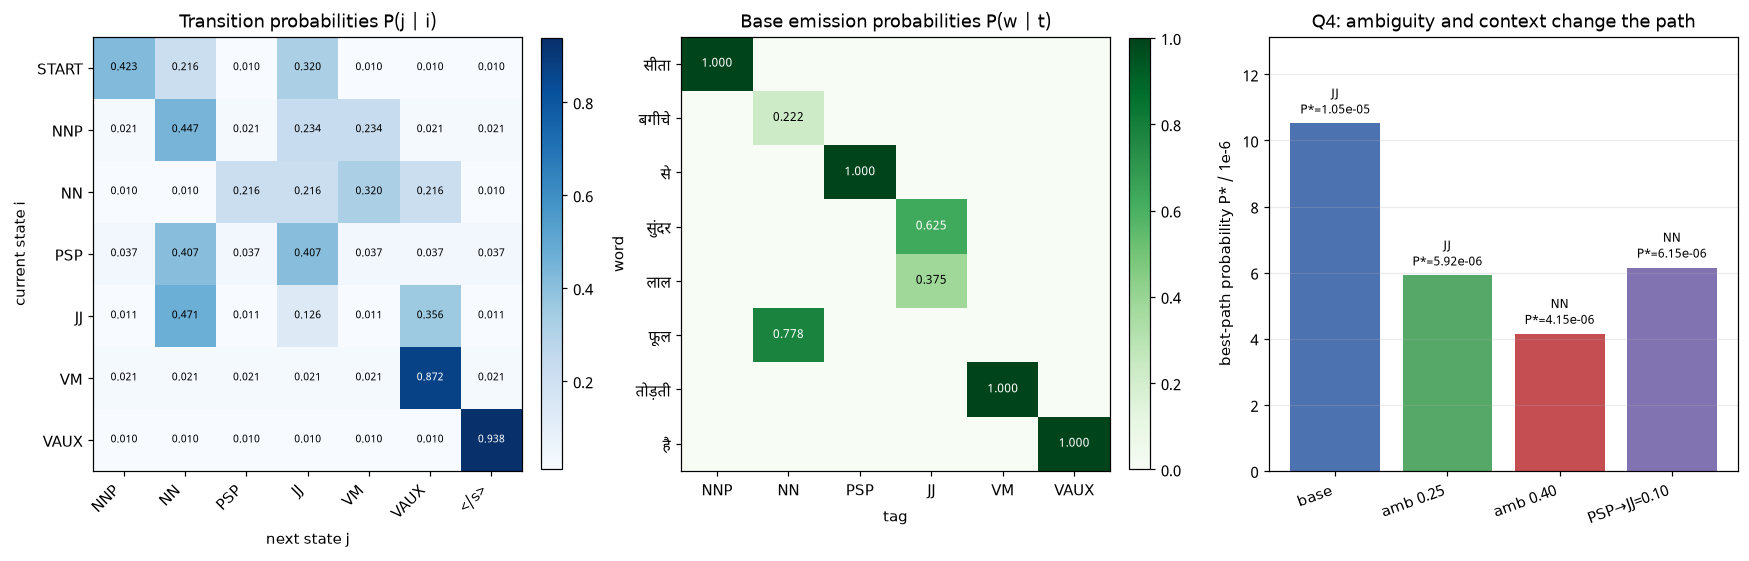

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))

# Panel 1: transition matrix.
states = [START] + TAGS
matrix = np.array([[transition[p][q] for q in NEXT_STATES] for p in states])
im = axes[0].imshow(matrix, cmap="Blues", aspect="auto")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        axes[0].text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center",
                     fontsize=7, color="white" if matrix[i, j] > 0.55 else "black")
axes[0].set_xticks(range(len(NEXT_STATES)), NEXT_STATES, rotation=45, ha="right")
axes[0].set_yticks(range(len(states)), [show_state(s) for s in states])
axes[0].set_title("Transition probabilities P(j | i)")
axes[0].set_xlabel("next state j")
axes[0].set_ylabel("current state i")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Panel 2: base emission matrix.
emission_matrix = np.array([[emission[tag].get(word, 0.0) for tag in TAGS]
                            for word in WORDS])
im = axes[1].imshow(emission_matrix, cmap="Greens", aspect="auto", vmin=0, vmax=1)
for i in range(emission_matrix.shape[0]):
    for j in range(emission_matrix.shape[1]):
        if emission_matrix[i, j] > 0:
            axes[1].text(j, i, f"{emission_matrix[i, j]:.3f}", ha="center", va="center",
                         fontsize=8, color="white" if emission_matrix[i, j] > 0.55 else "black")
axes[1].set_xticks(range(len(TAGS)), TAGS)
axes[1].set_yticks(range(len(WORDS)), WORDS)
axes[1].set_title("Base emission probabilities P(w | t)")
axes[1].set_xlabel("tag")
axes[1].set_ylabel("word")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

# Panel 3: Q4 sensitivity, shown as P* in units of 1e-6.
labels = ["base", "amb 0.25", "amb 0.40", "PSP→JJ=0.10"]
scores = [sequence_log_probability(TARGET, TARGET_TAGS),
          q4_results[0][2], q4_results[1][2], q4_results[2][2]]
chosen = ["JJ", "JJ", "NN", "NN"]
bars = axes[2].bar(range(4), [math.exp(s) * 1e6 for s in scores],
                   color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
axes[2].set_xticks(range(4), labels, rotation=20, ha="right")
axes[2].set_ylabel("best-path probability P* / 1e-6")
axes[2].set_title("Q4: ambiguity and context change the path")
for bar, score, tag in zip(bars, scores, chosen):
    axes[2].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.15,
                 f"{tag}\nP*={math.exp(score):.2e}",
                 ha="center", va="bottom", fontsize=8)
axes[2].set_ylim(0, max(math.exp(s) * 1e6 for s in scores) * 1.25)
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Verification

Four checks are run:

1. Every transition row sums to 1 and every emission column sums to 1, including the renormalised ambiguous tables.
2. The Viterbi path's own score, recomputed with `sequence_log_probability`, equals the score returned by the decoder.
3. A brute-force enumeration of all $6^n$ tag sequences gives the same best score as Viterbi, and the Viterbi path is one of the brute-force optima.
4. The target sentence is confirmed absent from the training corpus, so Q2–Q3 are decoding rather than memorisation.

For the eight-word target, the brute-force check visits $6^8=1{,}679{,}616$ paths. The Q5 sentences visit between $6^4=1{,}296$ and $6^7=279{,}936$ paths. This is small enough to run in a few seconds and strong enough to catch an indexing or backtracking bug.

In [10]:
def brute_force(words, trans=None, emis=None):
    '''Enumerate every tag sequence and return (best log score, all optimal paths).'''
    trans = trans or transition
    emis = emis or emission
    best_score = -math.inf
    best_paths = []
    for tags in itertools.product(TAGS, repeat=len(words)):
        score = logp(trans[START][tags[0]]) + logp(emis[tags[0]].get(words[0], 0.0))
        for i in range(1, len(words)):
            score += logp(trans[tags[i - 1]][tags[i]])
            score += logp(emis[tags[i]].get(words[i], 0.0))
        score += logp(trans[tags[-1]][END])
        if score > best_score + 1e-12:
            best_score = score
            best_paths = [tags]
        elif abs(score - best_score) <= 1e-12:
            best_paths.append(tags)
    return best_score, best_paths


checks = []
for prev in [START] + TAGS:
    checks.append((f"transition row {show_state(prev)!r} sums to 1",
                   abs(sum(transition[prev].values()) - 1.0) < 1e-12))
for tag in TAGS:
    checks.append((f"emission column {tag} sums to 1",
                   abs(sum(emission[tag].get(word, 0.0) for word in WORDS) - 1.0) < 1e-12))

target_path, _, _, target_log = viterbi(TARGET)
checks.append(("Viterbi path reproduces its score",
               abs(sequence_log_probability(TARGET, target_path) - target_log) < 1e-12))
checks.append(("target is absent from training", TARGET not in [w for w, _ in TAGGED_CORPUS]))

bf_score, bf_paths = brute_force(TARGET)
checks.append(("brute force matches Viterbi on target", abs(bf_score - target_log) < 1e-12))
checks.append((f"Viterbi path is an optimum ({len(bf_paths)} optimal path)",
               tuple(target_path) in bf_paths))

q5_emission = ambiguous_emission(0.25)
for words in Q5_SENTENCES:
    path, _, _, score = viterbi(words, emis=q5_emission)
    bf, paths = brute_force(words, emis=q5_emission)
    checks.append((f"Q5 {' '.join(words)} matches brute force ({len(paths)} optimum)",
                   abs(bf - score) < 1e-12 and tuple(path) in paths))

print_table(["check", "result"], [[name, "PASS" if ok else "FAIL"] for name, ok in checks],
            aligns=["<", "<"])
print(f"\nAll checks passed: {all(ok for _, ok in checks)}")

check                                                               result
--------------------------------------------------------------------------
transition row 'START' sums to 1                                    PASS  
transition row 'NNP' sums to 1                                      PASS  
transition row 'NN' sums to 1                                       PASS  
transition row 'PSP' sums to 1                                      PASS  
transition row 'JJ' sums to 1                                       PASS  
transition row 'VM' sums to 1                                       PASS  
transition row 'VAUX' sums to 1                                     PASS  
emission column NNP sums to 1                                       PASS  
emission column NN sums to 1                                        PASS  
emission column PSP sums to 1                                       PASS  
emission column JJ sums to 1                                        PASS  
emission column VM sums t

## What to remember for the viva

- **Observation** = word; **hidden state** = POS tag. The tag sequence is hidden, the words are observed.
- **Transition probability** $P(t_i\mid t_{i-1})$ is the chance of moving from one tag to the next; **emission probability** $P(w_i\mid t_i)$ is the chance that a tag produces a particular word.
- **Sequence probability** is the product of all transition and emission factors along a path, including `START` and `END`.
- **Viterbi** computes the best score for every prefix and tag, stores the best predecessor in a backpointer, then backtracks from the best final tag. It is dynamic programming, not exhaustive search.
- **Ambiguity** means one word has non-zero emission under more than one tag. The decision is not made by the emission alone: the surrounding transitions and the rest of the path also contribute. Q4 flips सुंदर from `JJ` to `NN` by raising its `NN` emission or by weakening `PSP→JJ`.
- The model is only as good as its corpus. Nine short sentences give unstable estimates, the emission table is deterministic for most words, and an unknown word would receive probability zero unless an unknown-word model were added.

A more complete tagger would use a larger annotated corpus, morphological features, a second-order transition table, and smoothing or a discriminative model such as a CRF for emission scores. The Viterbi recursion in this notebook is the same algorithm those systems use at decoding time.